# Étape 5 — Évaluation du modèle

**Termes techniques :** Accuracy, Precision, Recall, F1-score, matrice de confusion, prédiction, erreurs de classification


## Cellule 1 — Imports et configuration


In [9]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

PROJECT_DIR = Path.cwd()
while PROJECT_DIR != PROJECT_DIR.parent and not (PROJECT_DIR / "data" / "split" / "test.csv").is_file():
    PROJECT_DIR = PROJECT_DIR.parent
SPLIT_DIR = PROJECT_DIR / "data" / "split"
SELECTED_MODEL_PATH = PROJECT_DIR / "models" / "cnn_scenevision_selected.keras"
BASE_MODEL_PATH = PROJECT_DIR / "models" / "cnn_scenevision.keras"
MODEL_PATH = SELECTED_MODEL_PATH if SELECTED_MODEL_PATH.exists() else BASE_MODEL_PATH
sys.path.insert(0, str(PROJECT_DIR))
from src.data_pipeline import load_manifest

IMG_SIZE = (150, 150)
BATCH_SIZE = 32
test_table = pd.read_csv(SPLIT_DIR / "test.csv")
class_names = sorted(pd.read_csv(SPLIT_DIR / "train.csv")["label"].unique())
class_to_id = {name: index for index, name in enumerate(class_names)}
CLASSES = class_names
print("Images de test :", len(test_table))
print("Classes :", class_to_id)
print("Modèle disponible :", MODEL_PATH.exists())

Images réservées au test : 2556
Classes et ordre : {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}
Modèle disponible : True


## Cellule 2 — Création du jeu de test


In [10]:
test_ds = load_manifest(SPLIT_DIR / "test.csv", class_to_id, IMG_SIZE, BATCH_SIZE)
print("Batchs de test :", len(test_ds))

Images test : 2556 | batchs : 80


## Cellule 3 — Chargement du modèle


In [11]:
model = tf.keras.models.load_model(MODEL_PATH)
print("Modèle chargé.")
model.summary()

Modèle chargé.


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,487,380 (55.26 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,658,254 (36.84 MB)

## Cellule 4 — Prédictions sur le jeu de test


In [12]:
# Récupérer toutes les images, les vrais labels et les probabilités prédites
all_images  = []
all_labels  = []
all_probs   = []

for images, labels in test_ds:
    probs = model.predict(images, verbose=0)
    all_images.append(images.numpy())
    all_labels.append(labels.numpy())
    all_probs.append(probs)

all_images = np.concatenate(all_images)
all_labels = np.concatenate(all_labels)
all_probs  = np.concatenate(all_probs)

# La classe prédite = celle avec la probabilité la plus haute
all_preds = np.argmax(all_probs, axis=1)

print("Images de test :", len(all_labels))
print("Accuracy globale :", f"{np.mean(all_preds == all_labels):.2%}")

Images de test : 2556
Accuracy globale : 85.21%


## Cellule 5 — Rapport de classification


In [13]:
print(classification_report(all_labels, all_preds, target_names=CLASSES))

              precision    recall  f1-score   support

   buildings       0.85      0.78      0.81       394
      forest       0.95      0.98      0.96       412
     glacier       0.87      0.75      0.80       444
    mountain       0.78      0.84      0.81       456
         sea       0.85      0.90      0.88       417
      street       0.83      0.88      0.85       433

    accuracy                           0.85      2556
   macro avg       0.85      0.85      0.85      2556
weighted avg       0.85      0.85      0.85      2556



## Cellule 6 — Matrice de confusion


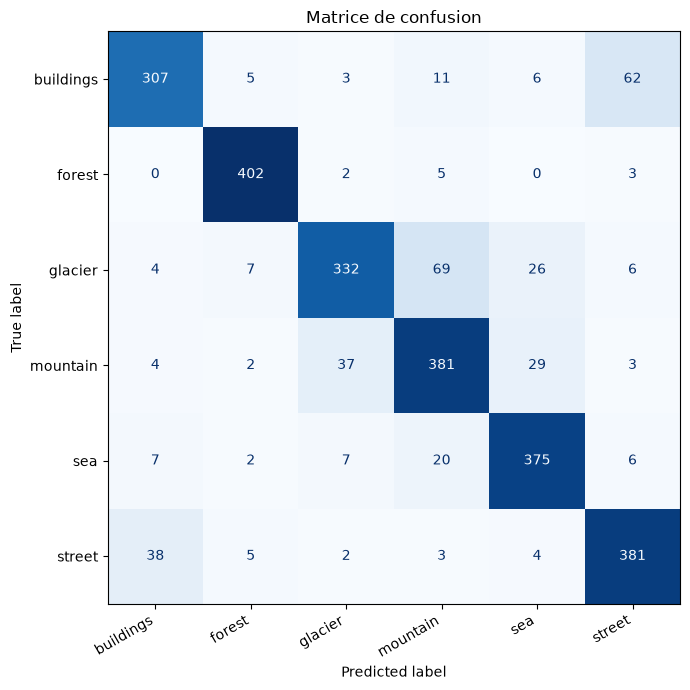

In [14]:
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(8, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES)
disp.plot(ax=ax, colorbar=False, cmap="Blues")
plt.title("Matrice de confusion")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Cellule 7 — Images mal classifiées


Images mal classifiées : 378 sur 2556


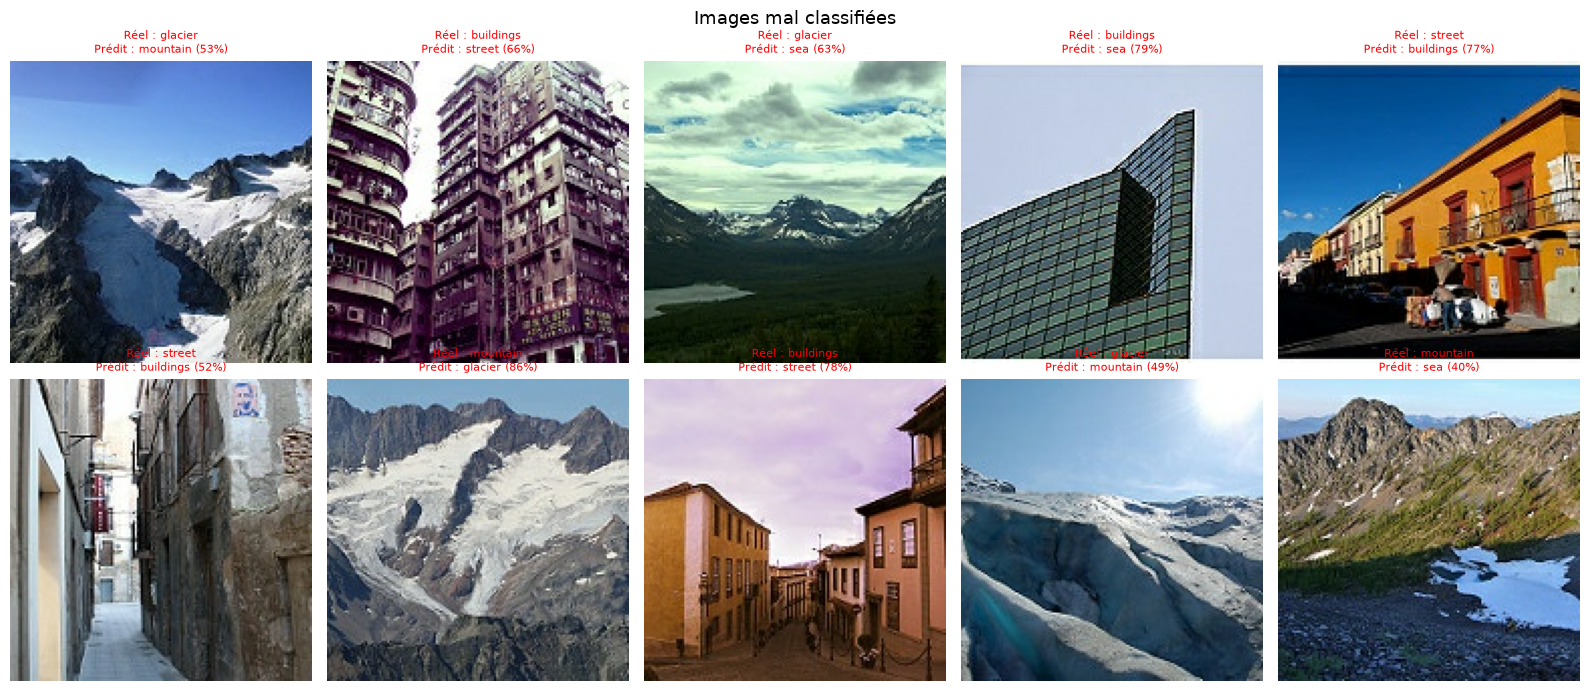

In [15]:
# Indices des images mal classifiées
wrong_idx = np.where(all_preds != all_labels)[0]
print(f"Images mal classifiées : {len(wrong_idx)} sur {len(all_labels)}")

# On affiche les 10 premières erreurs
sample = wrong_idx[:10]

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.flatten()

for i, idx in enumerate(sample):
    axes[i].imshow(all_images[idx])
    true_class  = CLASSES[all_labels[idx]]
    pred_class  = CLASSES[all_preds[idx]]
    confidence  = all_probs[idx][all_preds[idx]]
    axes[i].set_title(f"Réel : {true_class}\nPrédit : {pred_class} ({confidence:.0%})",
                      fontsize=8, color="red")
    axes[i].axis("off")

plt.suptitle("Images mal classifiées", fontsize=13)
plt.tight_layout()
plt.show()

## Cellule 8 — Bilan des performances


In [16]:
from sklearn.metrics import f1_score

accuracy   = np.mean(all_preds == all_labels)
f1_classes = f1_score(all_labels, all_preds, average=None)

best_class  = CLASSES[np.argmax(f1_classes)]
worst_class = CLASSES[np.argmin(f1_classes)]

print("=" * 45)
print(f"  Accuracy globale     : {accuracy:.2%}")
print(f"  Classe la mieux reconnue  : {best_class}  (F1 = {max(f1_classes):.2f})")
print(f"  Classe la plus difficile  : {worst_class} (F1 = {min(f1_classes):.2f})")
print("=" * 45)
print()
print("F1-score par classe :")
for cls, f1 in zip(CLASSES, f1_classes):
    barre = "█" * int(f1 * 20)
    print(f"  {cls:12s} {barre:20s} {f1:.2f}")

  Accuracy globale     : 85.21%
  Classe la mieux reconnue  : forest  (F1 = 0.96)
  Classe la plus difficile  : glacier (F1 = 0.80)

F1-score par classe :
  buildings    ████████████████     0.81
  forest       ███████████████████  0.96
  glacier      ████████████████     0.80
  mountain     ████████████████     0.81
  sea          █████████████████    0.88
  street       █████████████████    0.85


## Bilan et pistes d'amélioration
